1️⃣ Salary Benchmarking
Calculate the average salary across the entire company.
This will serve as the overall compensation benchmark.

In [1]:
import pandas as pd

# Load the dataset
df = pd.read_csv("/content/employee_performance_dataset.csv")

# Calculate company-wide average monthly salary
average_salary = df["Monthly_Salary"].mean()

print(f"Average monthly salary: ${average_salary:,.2f}")

Average monthly salary: $55,159.65


In [6]:
df

,Employee_ID,Department,Years_of_Experience,Monthly_Salary,Performance_Score,High_Performer
0,2001,HR,6,79835,2,False
1,2002,IT,4,44123,1,False
2,2003,IT,6,32640,6,False
3,2004,HR,9,22926,2,False
4,2005,Finance,12,55211,7,True
5,2006,IT,3,76930,4,False
6,2007,IT,6,67529,8,True
7,2008,Finance,10,30228,4,False
8,2009,Marketing,2,76912,2,False
9,2010,Finance,1,34797,10,True


2️⃣ Departmental Comparison
Group employees by Department.
Compute the average salary per department.
Identify which department has the highest average salary.

In [3]:
department_summary = (
    df.groupby("Department", as_index=False)
      .agg(
          average_monthly_salary=("Monthly_Salary", "mean"),
          employee_count=("Monthly_Salary", "count")
      )
      .round({"average_monthly_salary": 2})
      .sort_values("average_monthly_salary", ascending=False)
)

print("Average Monthly Salary by Department:\n")
print(department_summary.to_string(index=False))

highest = department_summary.iloc[0]
print(f"\nHighest-paid department: {highest['Department']} (${highest['average_monthly_salary']:,.2f})")

Average Monthly Salary by Department:

Department  average_monthly_salary  employee_count
 Marketing                65270.33               6
        IT                55305.50               4
        HR                52361.40               5
   Finance                45708.40               5

Highest-paid department: Marketing ($65,270.33)


3️⃣ Identify Top Talent
Create a new column called High_Performer where:
High_Performer = True  if Score ≥ 7  
High_Performer = False if Score < 7
This helps flag high-performing employees.

In [4]:
df["High_Performer"] = df["Performance_Score"] >= 7
print(df[["Employee_ID", "Department", "Performance_Score", "High_Performer"]])


    Employee_ID Department  Performance_Score  High_Performer
0          2001         HR                  2           False
1          2002         IT                  1           False
2          2003         IT                  6           False
3          2004         HR                  2           False
4          2005    Finance                  7            True
5          2006         IT                  4           False
6          2007         IT                  8            True
7          2008    Finance                  4           False
8          2009  Marketing                  2           False
9          2010    Finance                 10            True
10         2011  Marketing                  7            True
11         2012    Finance                  4           False
12         2013  Marketing                 10            True
13         2014         HR                  7            True
14         2015  Marketing                  6           False
15      

4️⃣ Headcount Analysis
Count the total number of High Performers in the company.
Provide a breakdown if necessary.


In [5]:
total_high_performers = df["High_Performer"].sum()

print("Total High Performers:", total_high_performers)

department_breakdown = (
    df[df["High_Performer"]]
    .groupby("Department")
    .size()
    .sort_values(ascending=False)
)

print("\nHigh Performers by Department:")
print(department_breakdown)

Total High Performers: 8

High Performers by Department:
Department
Marketing    3
Finance      2
HR           2
IT           1
dtype: int64


5️⃣ Visual Trend – Experience vs Salary
Create a Scatter Plot showing:
Experience vs. Salary
Include:

Chart title
Axis labels
Grid (optional)
Briefly observe whether salary increases with experience.

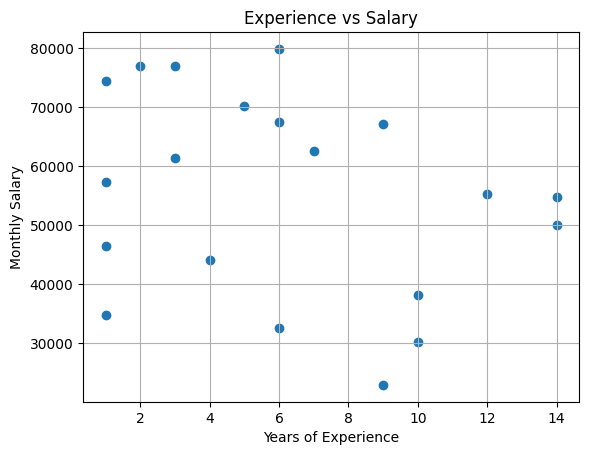

In [9]:
import matplotlib.pyplot as plt
plt.scatter(df['Years_of_Experience'], df['Monthly_Salary'])
plt.title('Experience vs Salary')
plt.xlabel('Years of Experience')
plt.ylabel('Monthly Salary')
plt.grid(True)
plt.show()

6️⃣ Performance Review by Department
Create a Bar Chart showing:
Department vs. Average Performance Score
Include:

Clear title
Axis labels
Proper formatting for readability

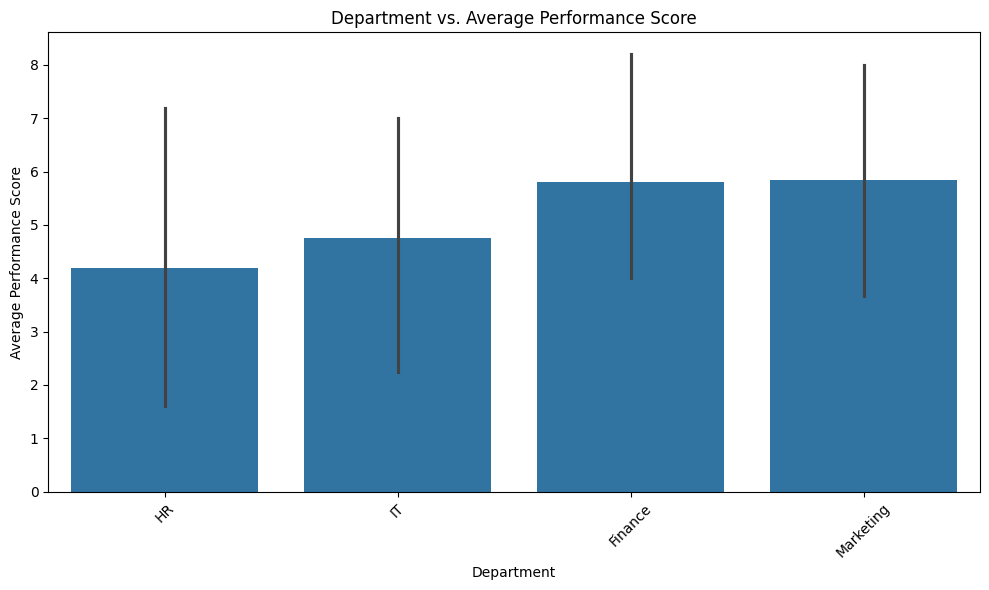

In [13]:
import seaborn as sns
plt.figure(figsize=(10, 6))
sns.barplot(x='Department', y='Performance_Score', data=df)
plt.title('Department vs. Average Performance Score')
plt.xlabel('Department')
plt.ylabel('Average Performance Score')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()